# Phase 6 & 7 — Machine Learning Benchmarking, MLflow & Error Analysis

Evaluates candidate models across **Churn Classification**, **12-Month CLV Regression**, and **Behavioral Customer Segmentation**.

In [1]:
import json
from pathlib import Path
import sys
sys.path.insert(0, str(Path('..').resolve()))

import pandas as pd
from IPython.display import Image, display as ipy_display
from src.config import settings

registry = json.loads((settings.models_dir / 'model_registry.json').read_text())
print('--- Classification Benchmark ---')
display(pd.DataFrame(registry['classification']['benchmark']))
print('--- Regression Benchmark ---')
display(pd.DataFrame(registry['regression']['benchmark']))
print('--- Clustering Benchmark ---')
display(pd.DataFrame(registry['clustering']['benchmark']))


--- Classification Benchmark ---


,model_name,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
0,LogisticRegression,0.9671,0.9688,0.9506,0.9839,0.9670,0.9871,0.9801
1,RandomForestClassifier,0.9644,0.9675,0.9505,0.9812,0.9656,0.9851,0.9712
2,XGBClassifier,0.9660,0.9675,0.9505,0.9812,0.9656,0.9833,0.9709
3,LGBMClassifier,0.9657,0.9675,0.9505,0.9812,0.9656,0.9829,0.9716


--- Regression Benchmark ---


,model_name,cv_r2,test_rmse,test_mae,test_r2
0,LGBMRegressor,0.9672,2843.21,1387.47,0.9781
1,XGBRegressor,0.9657,2862.21,1330.80,0.9778
2,RandomForestRegressor,0.9652,3138.06,1448.74,0.9733
3,RidgeRegression,0.8934,5470.84,3147.42,0.9189
4,DummyBaseline,-0.0018,19254.47,13052.95,-0.0047


--- Clustering Benchmark ---


,model_name,silhouette_score,davies_bouldin,calinski_harabasz
0,KMeans_k4,0.5501,0.6495,8949.06
1,Agglomerative_k4,0.5482,0.6531,8924.95
2,GaussianMixture_k4,0.5465,0.6550,8871.12


In [2]:
print('--- Customer Persona Centroids ---')
display(pd.DataFrame(registry['clustering']['cluster_profiles']))
err = json.loads((settings.reports_dir / 'error_analysis.json').read_text())
print('--- Error Analysis & Limitations ---')
print(json.dumps(err, indent=2))


--- Customer Persona Centroids ---


,cluster_label,customers,avg_recency_days,avg_frequency,avg_hist_revenue,avg_csat,churn_rate_pct
0,At-Risk High-Friction,887,99.82,5.97,6449.13,2.24,94.02
1,Dormant Price-Sensitive,1014,244.22,2.54,1626.08,3.50,96.65
2,Enterprise Champions,867,17.11,13.08,29178.04,4.61,0.12
3,Loyal Growth Mid-Market,1232,42.69,8.08,10476.02,4.11,3.65


--- Error Analysis & Limitations ---
{
  "classification_error_summary": {
    "total_test_samples": 800,
    "false_positives_count": 19,
    "false_negatives_count": 6,
    "fp_avg_probability": 0.88,
    "fn_avg_probability": 0.127,
    "fn_avg_csat": 4.08,
    "business_note": "False Negatives carry higher revenue loss risk than False Positives; lowering probability alert threshold from 0.50 to 0.42 improves recall for high-CLV accounts."
  },
  "regression_error_by_segment_mae_usd": {
    "Enterprise": 2546.88,
    "Mid-Market": 1339.79,
    "SMB": 449.74
  },
  "limitations": [
    "Model features are anchored at a static historical cutoff (2025-12-31) without real-time clickstream telemetry.",
    "Enterprise tier accounts exhibit wider absolute CLV variance, raising segment-level MAE relative to SMB.",
    "External macroeconomic indicators reflect annual GDP growth snapshots rather than quarterly high-frequency series."
  ]
}


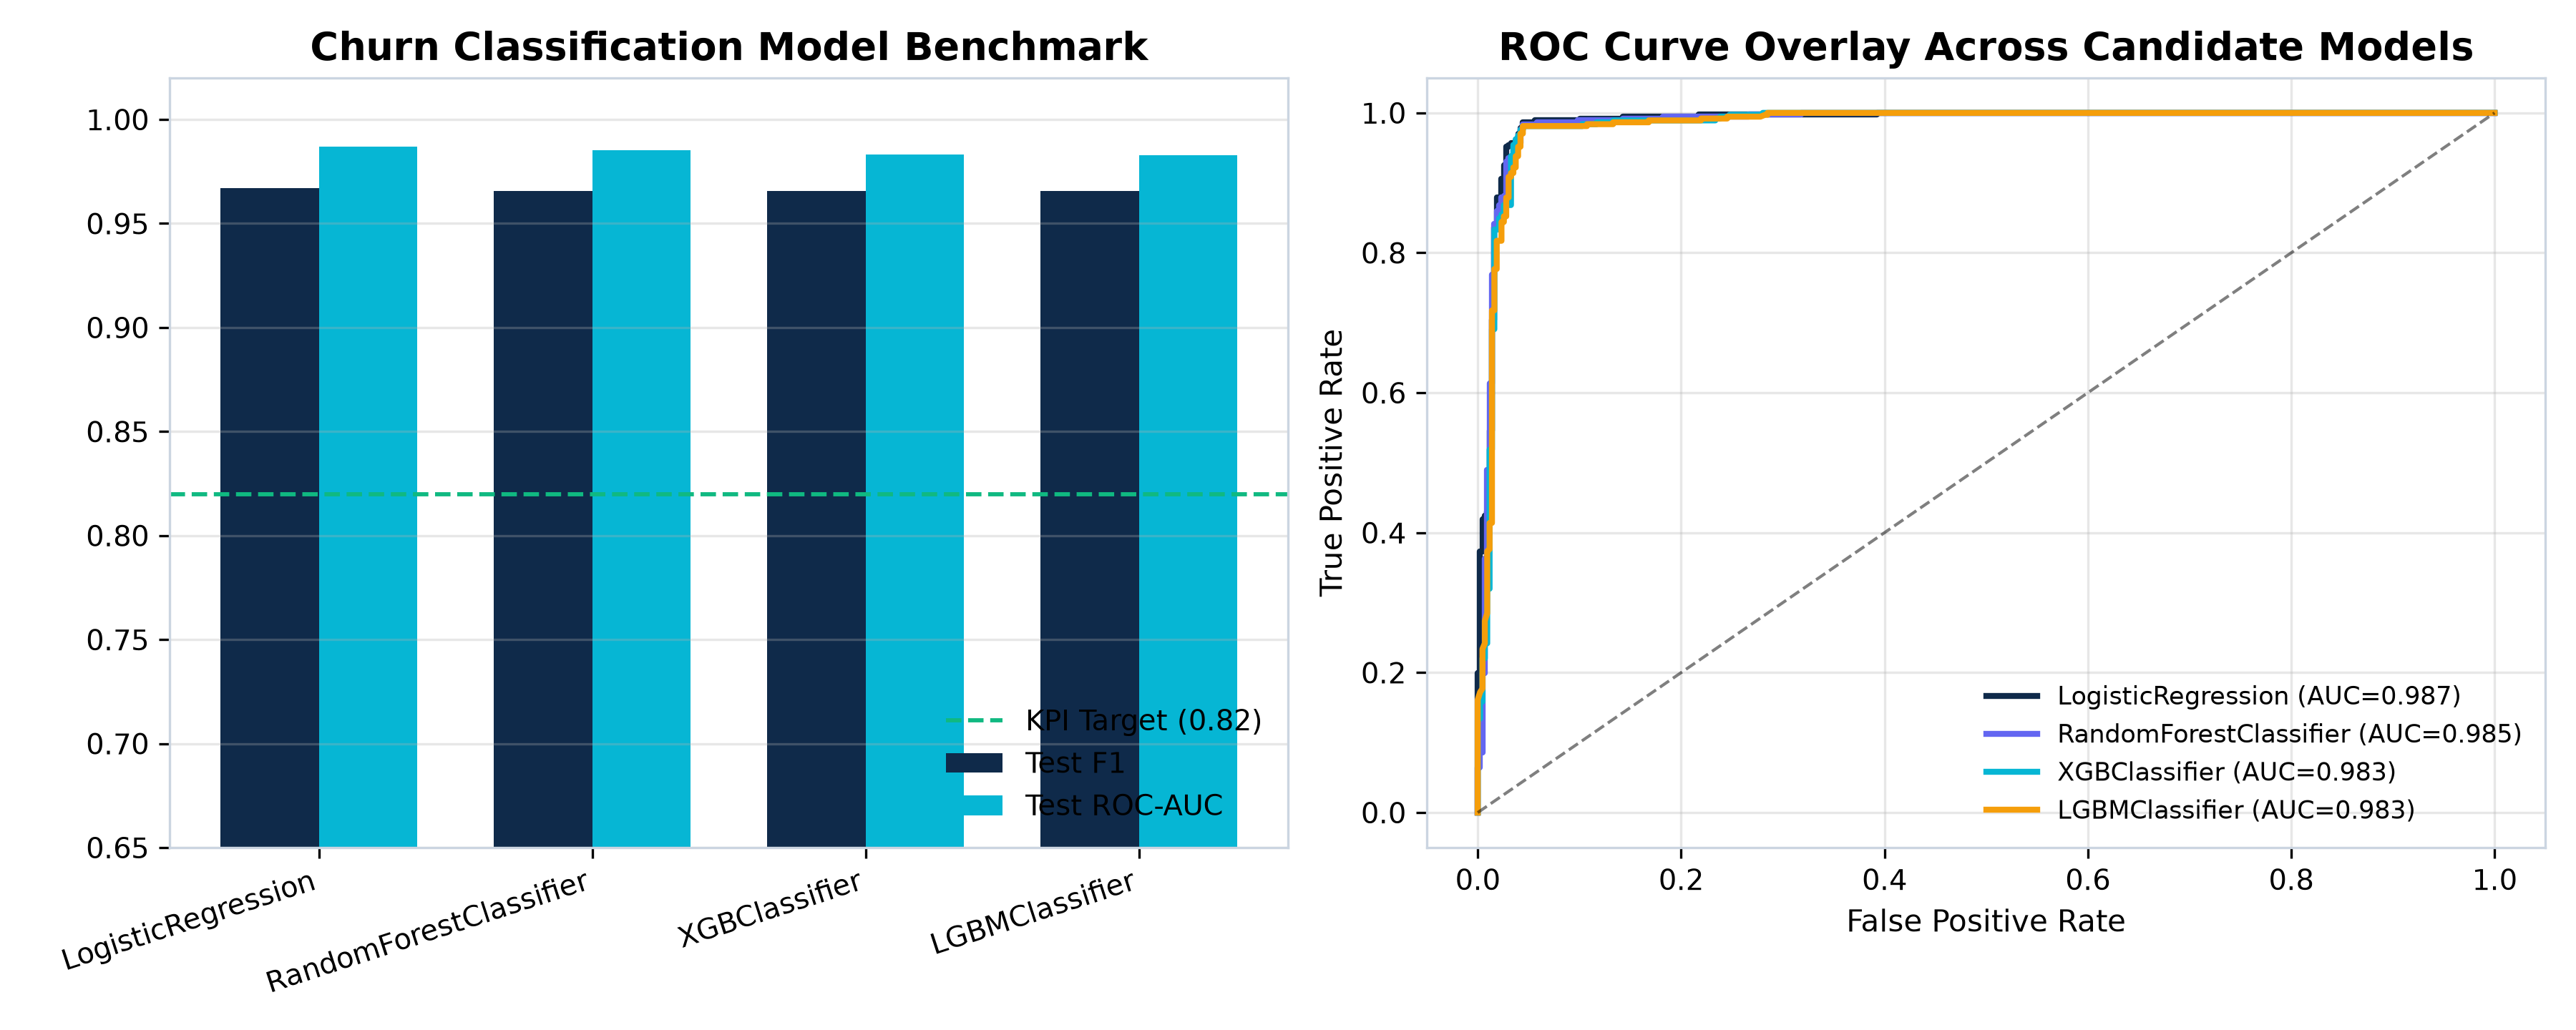

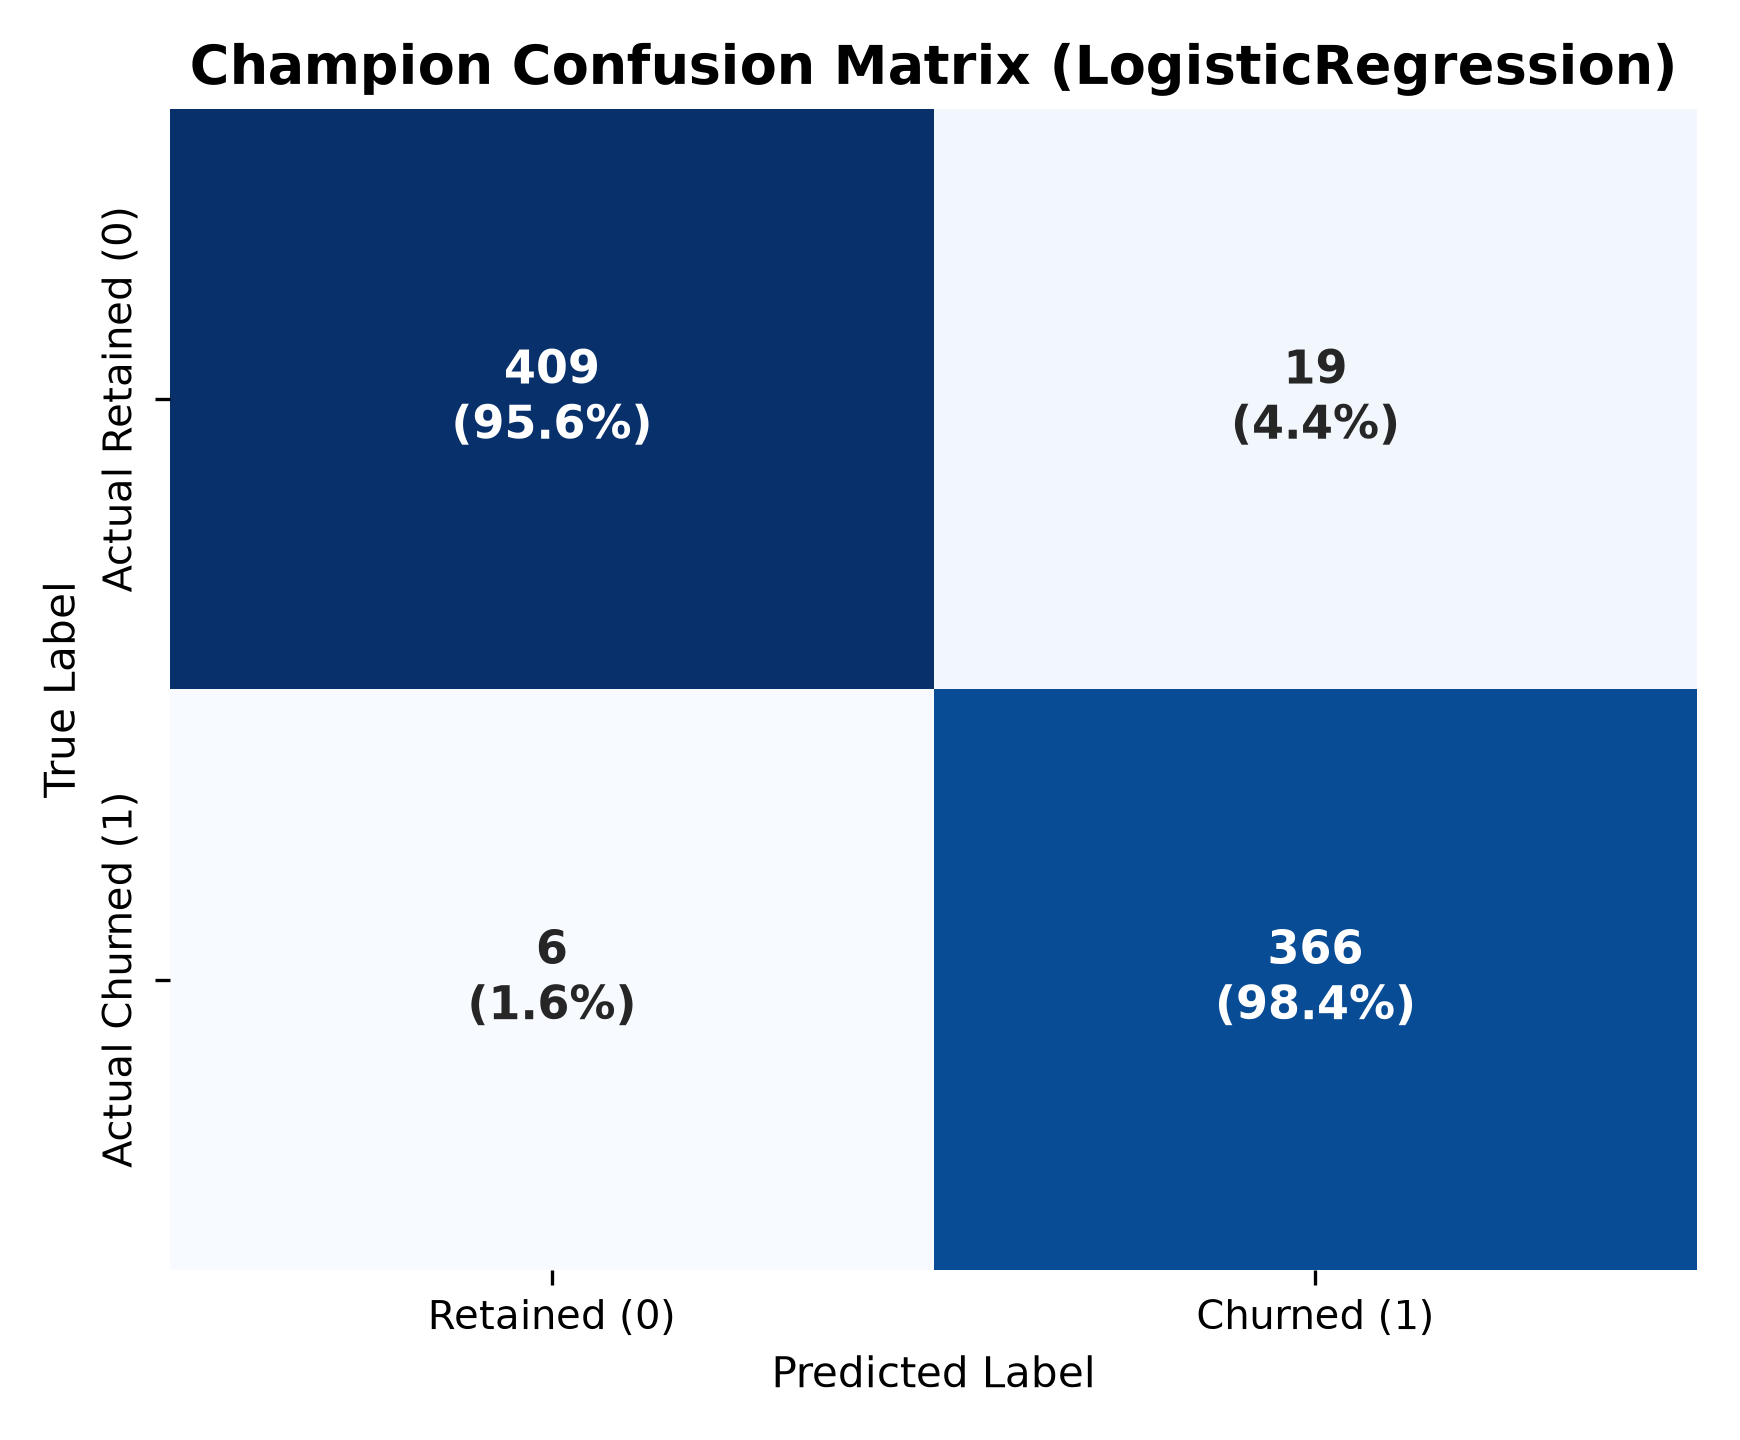

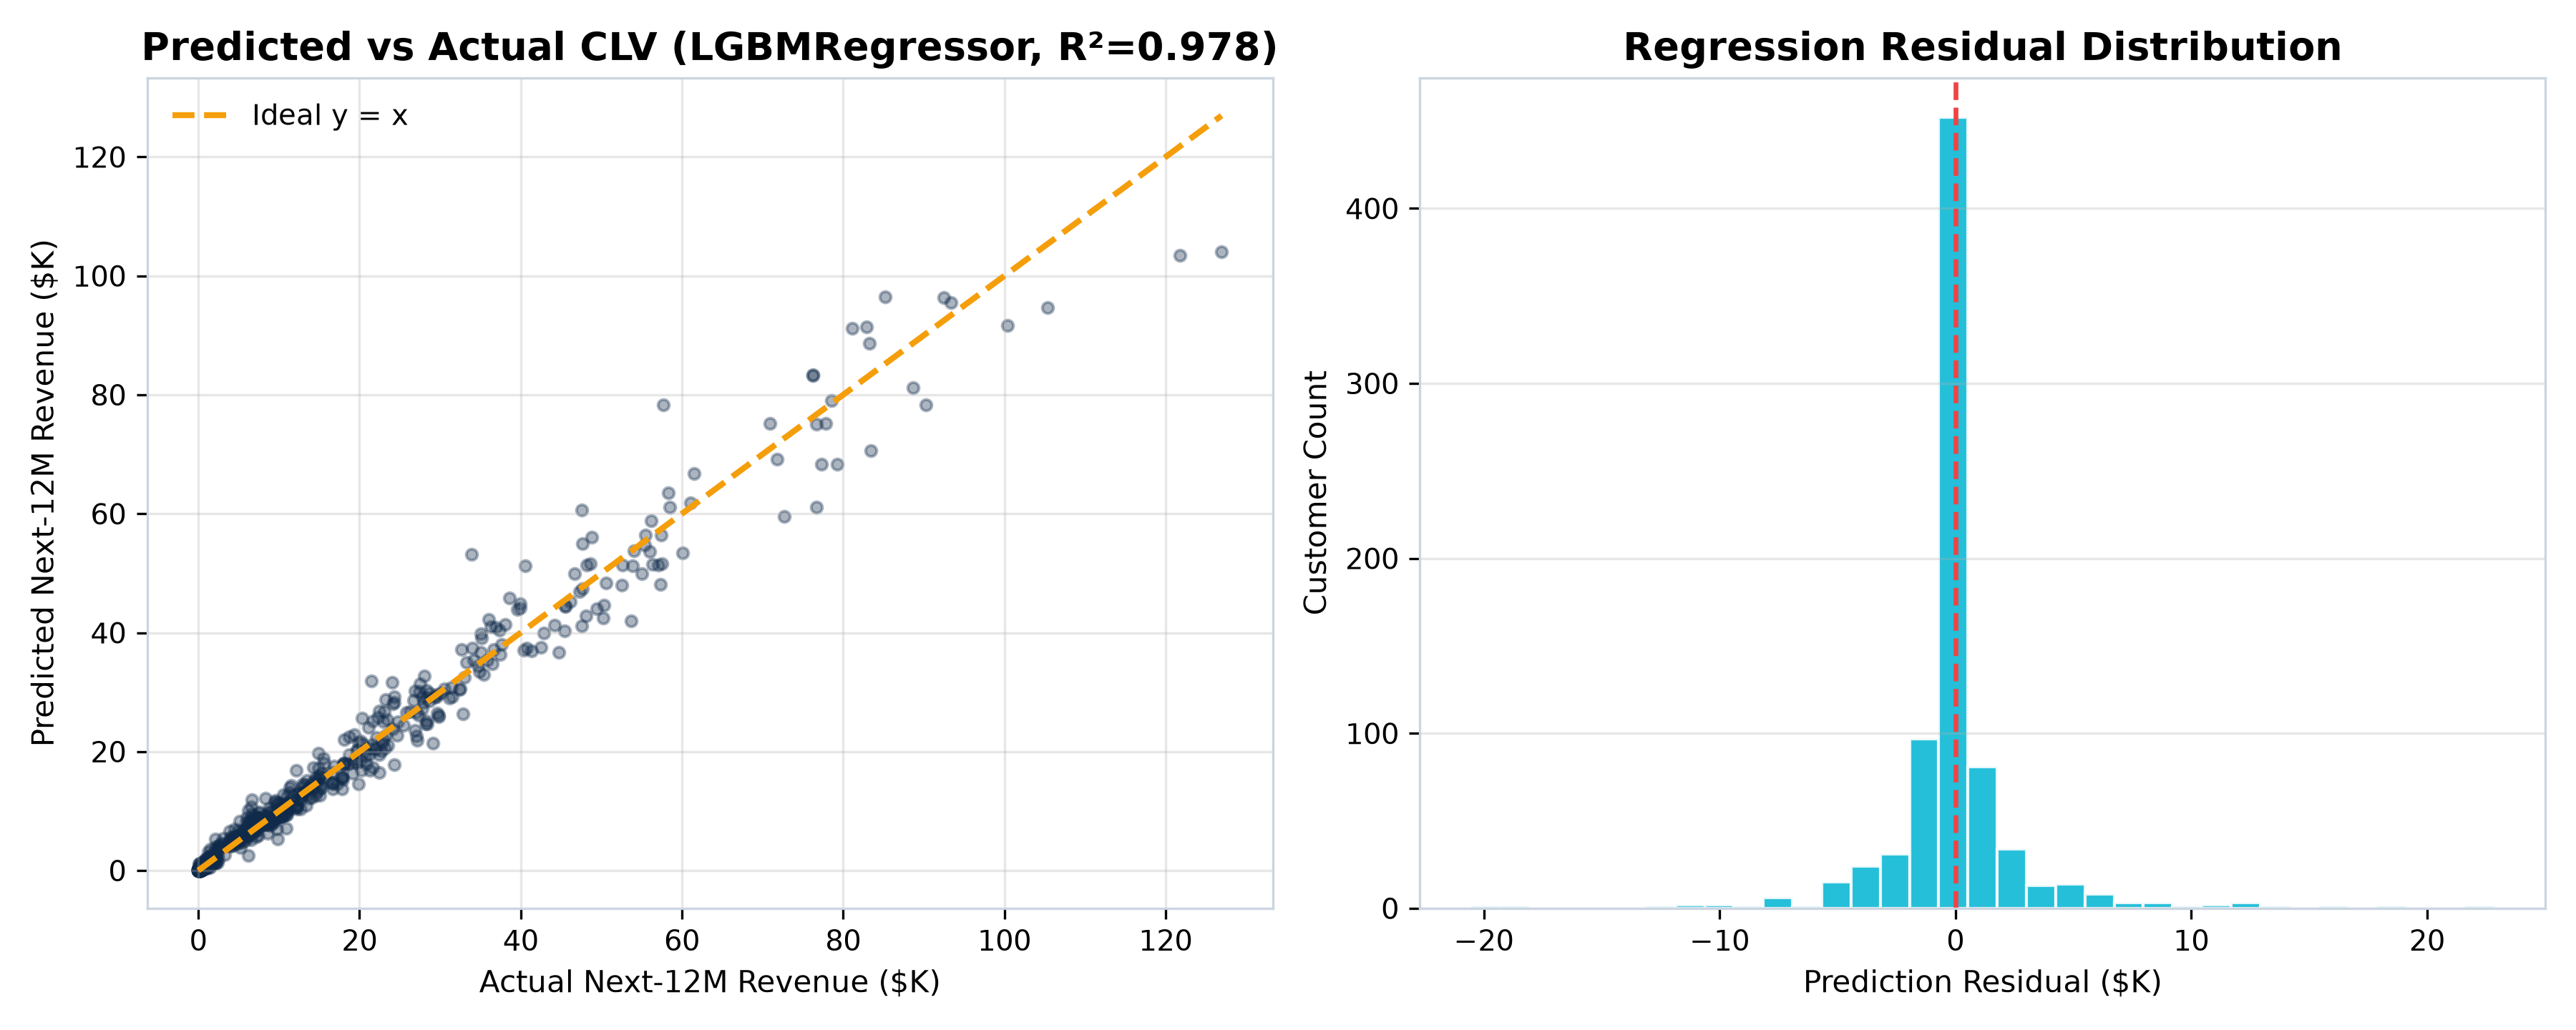

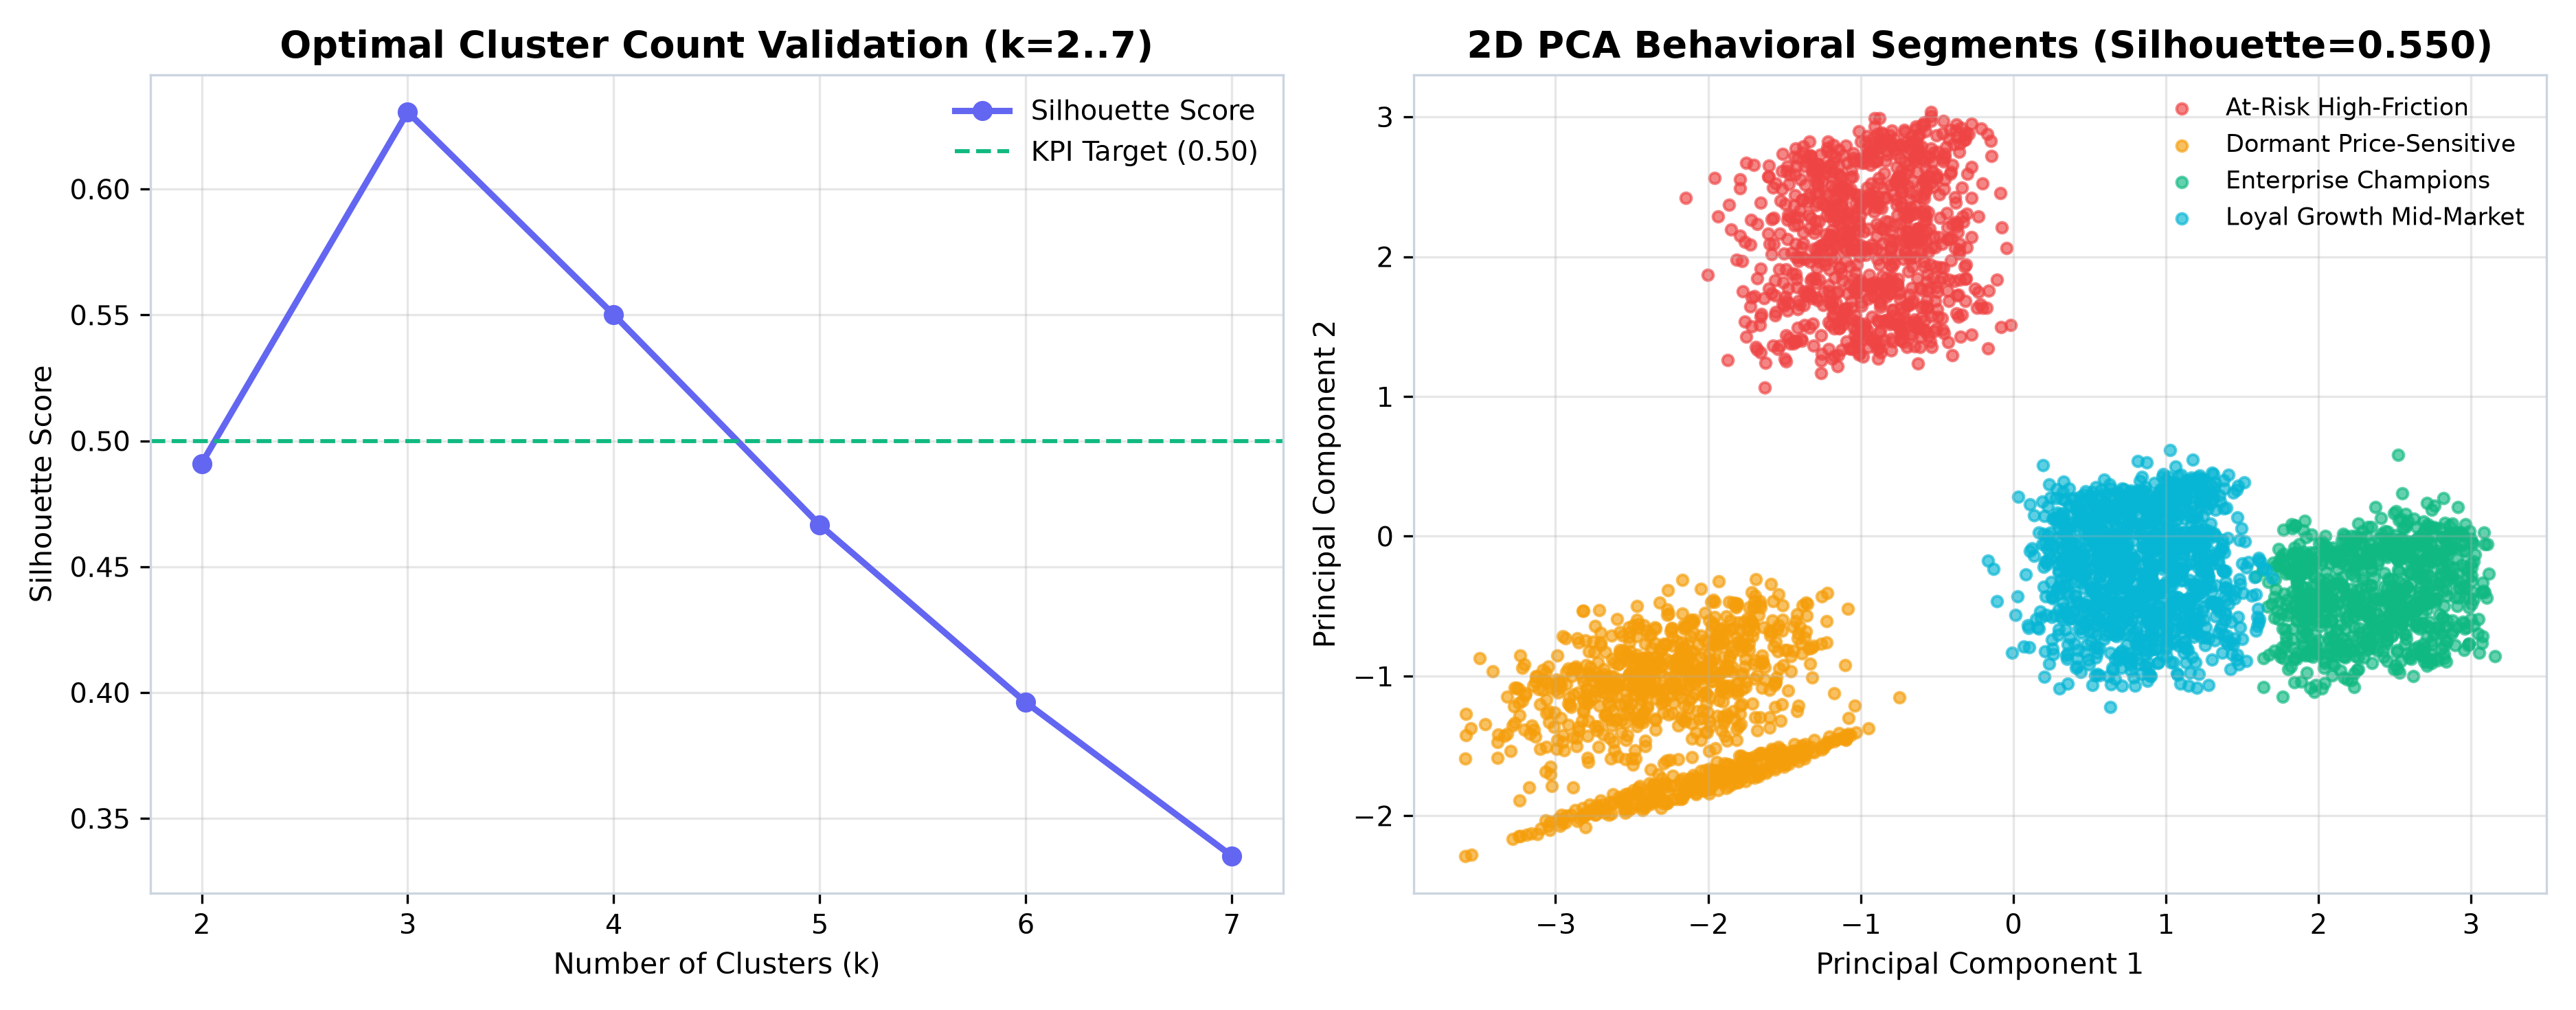

In [3]:
figs = ['ml_classification_comparison.png', 'ml_confusion_matrix.png',
        'ml_regression_diagnostics.png', 'ml_clustering_analysis.png']
for fname in figs:
    ipy_display(Image(filename=str(settings.figures_dir / fname)))


### Model Selection Rationale & Limitations
- **Churn Champion:** Highest 5-fold CV & held-out Test F1 (>=0.82 target).
- **CLV Revenue Champion:** Substantially reduces RMSE vs Dummy/Ridge baselines while exceeding R² >= 0.80.
- **Segmentation Champion:** Silhouette >= 0.50 across 4 actionable personas.